# 05 – Risk

Tests the portfolio thesis and quantifies risk, using the backtest of the current weights from notebook 04.

1. **Diversification between the blocks**: correlation between pies and between block A (Growth & Quality) and block B (Macro thesis), full period, sub-periods and rolling.
2. **Cross-link 6.6**: do both blocks move in the same direction when the real interest rate changes?
3. **VaR and Expected Shortfall**: historical, parametric (normal) and Monte Carlo (normal and Student-t), at 95% and 99%, over 1 day and 1 month, plus a VaR backtest.
4. **Risk contribution per pie** versus capital weight.
5. **Historical stress tests**: Covid crash 2020 and rate shock 2022.
6. **Currency risk**: listing versus economic currency.
7. **Hypothetical scenarios**: one per "world" of the investment thesis, from a factor model, and a Taiwan shock (cross-link 6.2) in two variants.

**Choices**: weekly returns (Friday close) for correlation, regressions and risk contribution, because daily returns of exchanges that close at different times understate co-movement; daily returns for VaR. Real rate: US 10-year TIPS yield (FRED `DFII10`).

**Caveat**: all history before 31-10-2026 is a backtest of today's selection (hindsight), with ~91–93% data coverage in 2020 and 2022 (the rest redistributed within the pie) and documented proxies.

## Setup

In [1]:
import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from portfolio_analysis.config import BLOCKS, TRADING_DAYS, WEEKS
from portfolio_analysis.performance import to_weekly
from portfolio_analysis.risk import (
    Z,
    ewma_volatility,
    historical_var_es,
    kupiec,
    normal_var_es,
    ols,
    risk_contribution,
    scenario_impact,
    simulate_portfolio,
)

In [2]:
PROCESSED_DIR = Path("../data/processed")
DB_PATH = PROCESSED_DIR / "portfolio.db"
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFII10"

MONTH_DAYS = 21
CONFIDENCE = [0.95, 0.99]
RECENT_DAYS = 2 * TRADING_DAYS
N_SIMULATIONS = 20_000
SEED = 42

SUBPERIODS = {
    "2019-2021": ("2019-01-01", "2021-12-31"),
    "2022": ("2022-01-01", "2022-12-31"),
    "2023-now": ("2023-01-01", "2100-01-01"),
}
STRESS_WINDOWS = {
    "Covid crash": ("2020-02-19", "2020-03-23"),
    "Rate shock 2022": ("2022-01-03", "2022-10-12"),
}

## Load data

In [3]:
holdings = pd.read_parquet(PROCESSED_DIR / "holdings.parquet")
returns_total = pd.read_parquet(PROCESSED_DIR / "returns_total_eur.parquet")
backtest = pd.read_parquet(PROCESSED_DIR / "backtest_returns.parquet")
pie_daily = pd.read_parquet(PROCESSED_DIR / "pie_returns.parquet").dropna()

pie_weights = holdings.groupby("pie")["weight_in_portfolio"].sum()
portfolio_daily = backtest["Portfolio (monthly rebalanced)"].dropna()
benchmark_daily = backtest["Main benchmark (monthly)"].dropna()

block_daily = pd.DataFrame({
    block: pie_daily[pies].mul(pie_weights[pies]).sum(axis=1) / pie_weights[pies].sum()
    for block, pies in BLOCKS.items()
})
print(pie_daily.shape, block_daily.shape)
pie_weights

(2025, 6) (2025, 2)


pie
AI Boom                    0.10
Energie                    0.18
Kwaliteit                  0.27
Mijnbouw                   0.17
Multipolaire Wereldorde    0.15
Thematisch                 0.13
Name: weight_in_portfolio, dtype: float64

In [4]:
pie_weekly = to_weekly(pie_daily).dropna()
block_weekly = to_weekly(block_daily).dropna()
portfolio_weekly = to_weekly(portfolio_daily).dropna()
pie_weekly.shape

(410, 6)

## 1. Do the blocks diversify each other?

Correlation of weekly returns. A correlation well below 1 between block A and block B supports the thesis that the blocks are complementary; the rolling view shows whether that holds in every regime, or breaks down exactly when it matters.

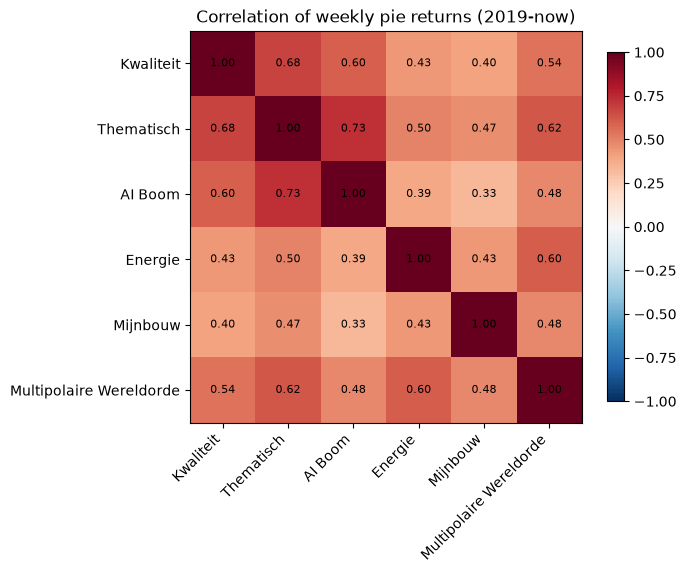

In [5]:
pie_corr = pie_weekly.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pie_corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(pie_corr)), pie_corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(pie_corr)), pie_corr.index)
for i in range(len(pie_corr)):
    for j in range(len(pie_corr)):
        ax.text(j, i, f"{pie_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation of weekly pie returns (2019-now)")
plt.tight_layout()
plt.show()

In [6]:
block_corr = {"full period": block_weekly["A"].corr(block_weekly["B"])}
for label, (start, end) in SUBPERIODS.items():
    window = block_weekly.loc[start:end]
    block_corr[label] = window["A"].corr(window["B"])

pd.Series(block_corr, name="corr(A, B)").round(3)

full period    0.616
2019-2021      0.766
2022           0.450
2023-now       0.529
Name: corr(A, B), dtype: float64

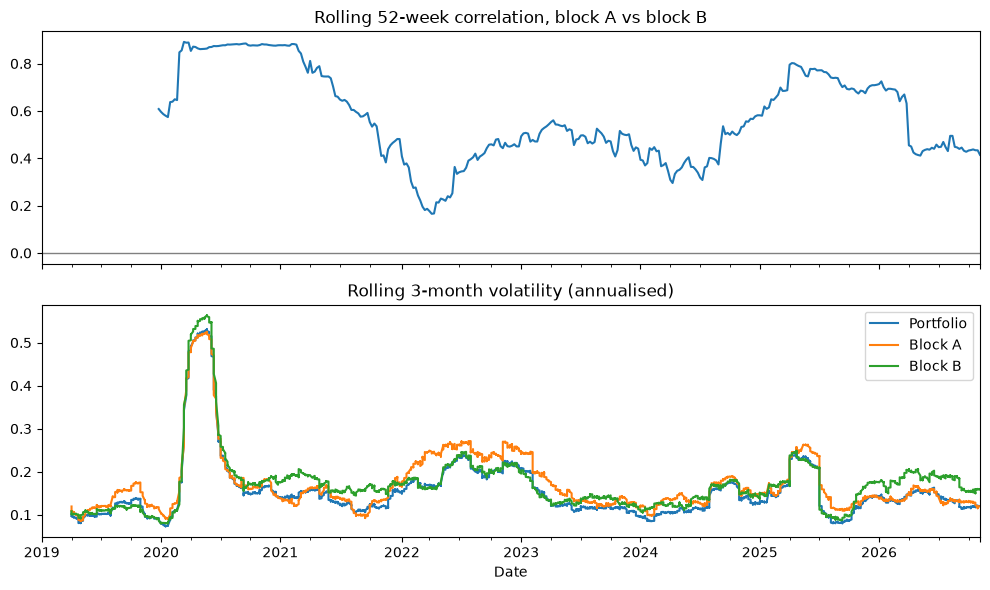

In [7]:
rolling_corr = block_weekly["A"].rolling(52).corr(block_weekly["B"])
rolling_vol = pd.concat({
    "Portfolio": portfolio_daily,
    "Block A": block_daily["A"],
    "Block B": block_daily["B"],
}, axis=1).rolling(63).std() * np.sqrt(TRADING_DAYS)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
rolling_corr.plot(ax=axes[0], title="Rolling 52-week correlation, block A vs block B")
axes[0].axhline(0, color="grey", linewidth=1)
rolling_vol.plot(ax=axes[1], title="Rolling 3-month volatility (annualised)")
plt.tight_layout()
plt.show()

## 2. Cross-link 6.6: the real interest rate

Weekly change in the US 10-year real yield (TIPS) in percentage points. For each block and pie we estimate the sensitivity of the weekly EUR return to that change, first on its own and then controlling for the equity market (MSCI World), so that the real-rate effect is not just the market effect. The thesis says the real rate is the one driver that moves **both** blocks in the **same** direction: both coefficients should then have the same sign. Note: returns are in EUR and the real yield is a USD rate, so part of the effect runs through EUR/USD. Standard errors are plain OLS (no correction for heteroskedasticity or autocorrelation).

Real yield from 2003-01-02 to 2026-11-03, last 2.65%


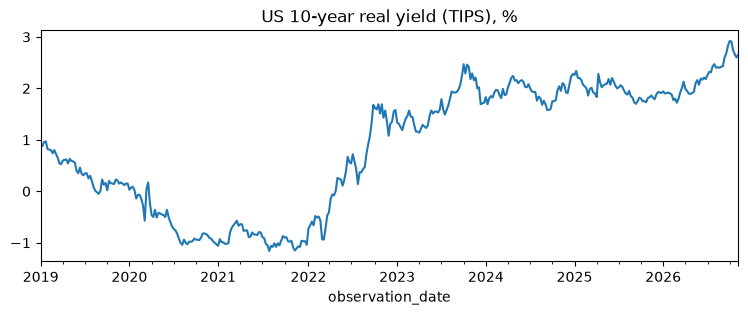

In [8]:
fred = pd.read_csv(FRED_URL, na_values=".")
fred = fred.set_index(pd.to_datetime(fred.iloc[:, 0]))["DFII10"].astype(float)
real_yield_weekly = fred.resample("W-FRI").last()
d_real = real_yield_weekly.diff().rename("d_real_yield")
market_weekly = to_weekly(returns_total["IWDA"]).rename("market")

print(f"Real yield from {fred.index.min().date()} to {fred.index.max().date()}, last {fred.dropna().iloc[-1]:.2f}%")
real_yield_weekly.loc["2019":].plot(figsize=(9, 3), title="US 10-year real yield (TIPS), %")
plt.show()

In [9]:
targets = pd.concat([block_weekly.add_prefix("Block "), pie_weekly], axis=1)
rows = {}
for name in targets.columns:
    simple = ols(targets[name], d_real.to_frame())
    controlled = ols(targets[name], pd.concat([d_real, market_weekly], axis=1))
    rows[name] = {
        "per +10bp (simple)": simple.loc["d_real_yield", "coef"] * 0.1,
        "t (simple)": simple.loc["d_real_yield", "t"],
        "per +10bp (market-controlled)": controlled.loc["d_real_yield", "coef"] * 0.1,
        "t (controlled)": controlled.loc["d_real_yield", "t"],
        "market beta": controlled.loc["market", "coef"],
        "n_weeks": simple.attrs["n"],
    }

real_rate_table = pd.DataFrame(rows).T
real_rate_table.round(4)

,per +10bp (simple),t (simple),per +10bp (market-controlled),t (controlled),market beta,n_weeks
Block A,-0.0060,-5.3666,-0.0017,-3.1207,1.0658,410.0
Block B,-0.0061,-5.3746,-0.0026,-3.1502,0.8476,410.0
Kwaliteit,-0.0070,-6.7426,-0.0034,-5.2111,0.8812,410.0
Thematisch,-0.0058,-3.9811,-0.0005,-0.5557,1.3075,410.0
AI Boom,-0.0036,-2.1987,0.0015,1.2251,1.2499,410.0
Energie,-0.0036,-2.6267,0.0003,0.2513,0.9404,410.0
Mijnbouw,-0.0117,-6.4936,-0.0083,-4.9731,0.8412,410.0
Multipolaire Wereldorde,-0.0027,-2.8676,0.0003,0.4873,0.7436,410.0


Read the coefficients as: the average weekly EUR return of the block or pie when the US real yield rises by 10 basis points. A |t| above roughly 2 means the effect is statistically distinguishable from zero.

## 3. Value-at-Risk and Expected Shortfall

Loss figures are shown as positive percentages of portfolio value. Two estimation windows: the full period since 2019 (including the Covid crash) and the most recent two years.

- **Historical**: the empirical quantile of returns; 1-month uses overlapping 21-day returns, which are not independent, so treat it as indicative.
- **Parametric (normal)**: mean and standard deviation, scaled to 1 month with the square-root-of-time rule (assumes independent returns).
- **Monte Carlo**: joint simulation of the six pies (weights fixed at target) from a multivariate normal and a multivariate Student-t with the same covariance; the degrees of freedom follow from the excess kurtosis of the portfolio.

In [10]:
windows = {"full period": portfolio_daily, "last 2 years": portfolio_daily.iloc[-RECENT_DAYS:]}
var_rows = []
for window_name, r in windows.items():
    pies = pie_daily.loc[r.index.min():r.index.max()]
    monthly_overlapping = (1 + r).rolling(MONTH_DAYS).apply(np.prod, raw=True).dropna() - 1
    excess_kurtosis = r.kurt()
    nu = float(np.clip(6 / max(excess_kurtosis, 0.01) + 4, 3, 30))
    sims = {
        "Monte Carlo (normal)": simulate_portfolio(pies, pie_weights, N_SIMULATIONS, MONTH_DAYS, "normal"),
        f"Monte Carlo (t, nu={nu:.1f})": simulate_portfolio(pies, pie_weights, N_SIMULATIONS, MONTH_DAYS, "t", nu),
    }
    for level in CONFIDENCE:
        results = {
            "Historical": (historical_var_es(r, level), historical_var_es(monthly_overlapping, level)),
            "Parametric (normal)": (
                normal_var_es(r.mean(), r.std(), level),
                normal_var_es(r.mean() * MONTH_DAYS, r.std() * np.sqrt(MONTH_DAYS), level),
            ),
        }
        for method, (one_day, one_month) in sims.items():
            results[method] = (historical_var_es(one_day, level), historical_var_es(one_month, level))
        for method, ((var_1d, es_1d), (var_1m, es_1m)) in results.items():
            var_rows.append({
                "window": window_name, "confidence": level, "method": method,
                "VaR 1d": var_1d, "ES 1d": es_1d, "VaR 1m": var_1m, "ES 1m": es_1m,
            })

var_table = pd.DataFrame(var_rows)
(var_table.set_index(["window", "confidence", "method"]) * 100).round(2)

VaR 1d  ES 1d  VaR 1m  ES 1m
window       confidence method                                               
full period  0.95       Historical                 1.56   2.56    5.82  11.19
                        Parametric (normal)        1.68   2.13    6.39   8.45
                        Monte Carlo (normal)       1.67   2.12    6.21   8.13
                        Monte Carlo (t, nu=4.5)    1.55   2.32    6.22   8.36
             0.99       Historical                 2.89   4.72   12.97  23.44
                        Parametric (normal)        2.42   2.78    9.74  11.41
                        Monte Carlo (normal)       2.41   2.77    9.28  10.84
                        Monte Carlo (t, nu=4.5)    2.73   3.69    9.56  11.64
last 2 years 0.95       Historical                 1.34   2.12    6.55   8.48
                        Parametric (normal)        1.45   1.83    5.62   7.38
                        Monte Carlo (normal)       1.46   1.84    5.51   7.16
                        Monte Carlo (t, nu=5.0)    1.39   2.03    5.50   7.27
             0.99       Historical                 2.02   3.80   10.17  11.13
                        Parametric (normal)        2.08   2.39    8.49   9.92
                        Monte Carlo (normal)       2.09   2.39    8.17   9.51
                        Monte Carlo (t, nu=5.0)    2.34   3.19    8.28   9.96

**VaR backtest.** Does a 99% one-day VaR actually hold? Each day the VaR is estimated using only information up to the previous day (out of sample), and we count how often the next day's loss is larger. Expected: 1% of days. The Kupiec test compares the observed with the expected exceedance rate; a statistic above 3.84 rejects the model at 5% significance. This is the logic behind the Basel traffic-light approach.

Four models are compared. The two simple ones use a fixed 250-day window and react slowly when volatility changes. **EWMA** (RiskMetrics, lambda = 0.94) gives recent days more weight, so the volatility estimate jumps when markets become turbulent. **Filtered historical simulation (FHS)** combines both: historical returns are first divided by their EWMA volatility (standardised), and the empirical quantile of those standardised returns is scaled back with today's volatility. It keeps the fat tails of the data and adapts to the current regime.

In [11]:
level = 0.99
z99 = Z.inv_cdf(1 - level)
r = portfolio_daily
sigma_ewma = ewma_volatility(r)
standardised = r / sigma_ewma

var_models = {
    "Historical (250d)": -r.rolling(250).quantile(1 - level).shift(1),
    "Normal (250d)": -(r.rolling(250).mean().shift(1) + z99 * r.rolling(250).std().shift(1)),
    "EWMA (normal)": -z99 * sigma_ewma,
    "Filtered historical (250d)": -standardised.rolling(250).quantile(1 - level).shift(1) * sigma_ewma,
}
var_paths = pd.DataFrame(var_models).dropna()

backtest_rows = {}
for name in var_paths.columns:
    hits = int((r[var_paths.index] < -var_paths[name]).sum())
    n = len(var_paths)
    backtest_rows[name] = {"days": n, "exceedances": hits, "rate": hits / n, "expected": n * (1 - level), "kupiec_LR": kupiec(hits, n, 1 - level)}

var_backtest = pd.DataFrame(backtest_rows).T
var_backtest.round(4)

,days,exceedances,rate,expected,kupiec_LR
Historical (250d),1775.0,28.0,0.0158,17.75,5.0858
Normal (250d),1775.0,41.0,0.0231,17.75,22.4583
EWMA (normal),1775.0,39.0,0.0220,17.75,19.1578
Filtered historical (250d),1775.0,19.0,0.0107,17.75,0.0869


In [12]:
next_sigma = np.sqrt(0.94 * sigma_ewma.iloc[-1] ** 2 + 0.06 * r.iloc[-1] ** 2)
current_var = pd.Series({
    "Historical (full period)": historical_var_es(r, level)[0],
    "Historical (last 250d)": -r.iloc[-250:].quantile(1 - level),
    "EWMA (normal)": -z99 * next_sigma,
    "Filtered historical": -standardised.iloc[-250:].quantile(1 - level) * next_sigma,
}, name="99% 1-day VaR for the next trading day")
print(f"EWMA volatility now: {next_sigma * np.sqrt(TRADING_DAYS):.1%} annualised")
(current_var * 100).round(2)

EWMA volatility now: 13.0% annualised


Historical (full period)    2.89
Historical (last 250d)      1.95
EWMA (normal)               1.91
Filtered historical         1.98
Name: 99% 1-day VaR for the next trading day, dtype: float64

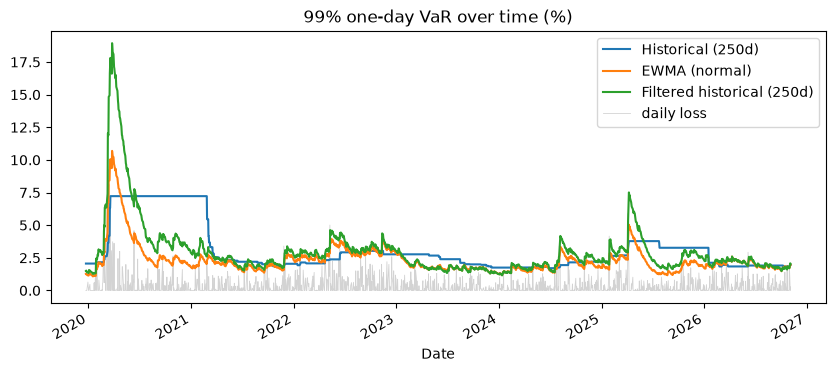

In [13]:
ax = (var_paths[["Historical (250d)", "EWMA (normal)", "Filtered historical (250d)"]] * 100).plot(figsize=(10, 4), title="99% one-day VaR over time (%)")
(-r[var_paths.index] * 100).clip(lower=0).plot(ax=ax, color="lightgrey", linewidth=0.6, label="daily loss", zorder=0)
ax.legend()
plt.show()

## 4. Risk contribution per pie

Euler decomposition of portfolio volatility (weekly returns): the contribution of pie *i* is its weight times the covariance of the pie with the portfolio, divided by portfolio volatility. Contributions add up to 100%. A pie whose share of risk exceeds its share of capital is a risk concentration.

In [14]:
rc_rows = {}
for label, (start, end) in {"full period": ("2019-01-01", "2100-01-01"), **SUBPERIODS}.items():
    rc_rows[label] = risk_contribution(pie_weekly.loc[start:end], pie_weights)

risk_contrib = pd.DataFrame(rc_rows)
risk_contrib.insert(0, "capital weight", pie_weights)
block_of = {pie: block for block, pies in BLOCKS.items() for pie in pies}
print((risk_contrib.groupby(block_of).sum() * 100).round(1))
(risk_contrib * 100).round(1)

   capital weight  full period  2019-2021  2022  2023-now
A            50.0         49.7       46.3  56.8      50.6
B            50.0         50.3       53.7  43.2      49.4


,capital weight,full period,2019-2021,2022,2023-now
Kwaliteit,27.0,22.8,22.9,27.8,19.9
Thematisch,13.0,15.5,14.2,15.8,16.9
AI Boom,10.0,11.5,9.2,13.1,13.9
Energie,18.0,17.2,20.6,16.6,12.9
Mijnbouw,17.0,22.5,20.4,19.5,27.2
Multipolaire Wereldorde,15.0,10.6,12.6,7.2,9.4


## 5. Historical stress tests

**Historical**: cumulative return over the stress window (peak to trough of global equities), for the portfolio, the blocks, the pies and the main benchmark. Coverage shows the share of today's weight that had data at the start of the window; the rest was redistributed within its pie.

In [15]:
started = returns_total[holdings["ticker"]].notna().cummax()
weight_by_ticker = holdings.set_index("ticker")["weight_in_portfolio"]

stress_rows = {}
for name, (start, end) in STRESS_WINDOWS.items():
    window = slice(pd.Timestamp(start) + pd.Timedelta(days=1), end)
    cumulative = lambda r: (1 + r.loc[window]).prod() - 1
    row = {"Portfolio": cumulative(portfolio_daily), "Main benchmark": cumulative(benchmark_daily)}
    row.update({f"Block {b}": cumulative(block_daily[b]) for b in BLOCKS})
    row.update({pie: cumulative(pie_daily[pie]) for pie in pie_daily.columns})
    row["coverage at start"] = (started.loc[:start].iloc[-1] * weight_by_ticker).sum()
    stress_rows[f"{name} ({start} to {end})"] = row

stress_table = pd.DataFrame(stress_rows)
(stress_table * 100).round(1)

,Covid crash (2020-02-19 to 2020-03-23),Rate shock 2022 (2022-01-03 to 2022-10-12)
Portfolio,-35.3,-7.4
Main benchmark,-28.6,1.9
Block A,-32.3,-24.5
Block B,-38.1,12.6
Kwaliteit,-31.2,-18.6
Thematisch,-35.5,-31.9
AI Boom,-31.3,-32.3
Energie,-43.7,45.5
Mijnbouw,-32.5,-11.8
Multipolaire Wereldorde,-38.3,6.4


## 6. Currency risk: listing versus economic currency

Two views. **Exposure**: the currency basket implied by the listing currency versus the economic currency split (notebook 01), and the volatility of each basket from ECB rates (only currencies with an ECB series; Other DM and EM are reported as unmodelled). **Empirical**: a regression of the portfolio's weekly EUR return on world equities in USD and on the USD itself; the USD coefficient estimates the effective USD exposure, to compare with the 44% listing and 49% economic USD share.

In [16]:
with sqlite3.connect(DB_PATH) as con:
    fx_long = pd.read_sql("SELECT date, currency, eur_rate FROM fx_ecb", con, parse_dates=["date"])
fx = fx_long.pivot(index="date", columns="currency", values="eur_rate").sort_index()
fx_returns = fx.shift(1) / fx - 1  # return of holding the foreign currency for a EUR investor
fx_weekly = to_weekly(fx_returns).dropna(how="all")

listing_exposure = holdings.groupby("listing_currency")["weight_in_portfolio"].sum()
econ_columns = {"econ_usd": "USD", "econ_eur": "EUR", "econ_gbp": "GBP", "econ_chf": "CHF", "econ_cad": "CAD", "econ_other_dm": "Other DM", "econ_em": "EM"}
economic_exposure = (holdings[list(econ_columns)].mul(holdings["weight_in_portfolio"], axis=0).sum()).rename(index=econ_columns)

exposure = pd.DataFrame({"listing": listing_exposure, "economic": economic_exposure}).fillna(0)
modelled = [c for c in exposure.index if c in fx_weekly.columns]
fx_vol = {
    view: (fx_weekly[modelled] @ exposure.loc[modelled, view]).std() * np.sqrt(WEEKS)
    for view in exposure.columns
}
print("Annualised FX volatility of the modelled basket:", {k: round(v, 4) for k, v in fx_vol.items()})
print("Unmodelled share (Other DM + EM):", exposure.loc[["Other DM", "EM"]].sum().round(4).to_dict())
exposure.round(4)

Annualised FX volatility of the modelled basket: {'listing': np.float64(0.0347), 'economic': np.float64(0.0407)}
Unmodelled share (Other DM + EM): {'listing': 0.0, 'economic': 0.2322}


,listing,economic
CAD,0.0254,0.1337
CHF,0.0459,0.0459
EM,0.0000,0.1426
EUR,0.3795,0.0826
GBP,0.1089,0.0166
Other DM,0.0000,0.0896
USD,0.4403,0.4890


In [17]:
iwda_weekly = to_weekly(returns_total["IWDA"])
usd_weekly = fx_weekly["USD"]
world_in_usd = ((1 + iwda_weekly) / (1 + usd_weekly) - 1).rename("world equity (USD)")

usd_model = ols(portfolio_weekly, pd.concat([world_in_usd, usd_weekly.rename("USD")], axis=1))
print(f"R2 = {usd_model.attrs['r2']:.3f}, n = {usd_model.attrs['n']} weeks")
usd_model.round(4)

R2 = 0.814, n = 410 weeks


,coef,se,t
const,0.0011,0.0005,2.1624
world equity (USD),0.9806,0.0234,41.8885
USD,0.6727,0.0554,12.1488


## 7. Hypothetical scenarios

**A factor model per pie.** Weekly pie returns (EUR) are regressed on four factors: world equities in USD, the change in the US 10-year real yield (percentage points), the USD (return of holding dollars for a EUR investor) and broad commodities in USD (CMOD). A scenario is a set of factor moves; its impact on a pie is the sum of sensitivity times move, and the portfolio impact is the target-weighted sum over pies.

**Limits.** The model is linear and estimated on weekly data, so it is least reliable for very large moves; it ignores the intercept (no alpha is assumed) and compounding; and the scenario moves are **assumptions**, anchored on historical episodes but not forecasts. As a check, the model is first applied to the actual factor moves of the 2022 rate shock and compared with what really happened.

In [18]:
cmod_usd = ((1 + to_weekly(returns_total["CMOD"])) / (1 + usd_weekly) - 1).rename("commodities (USD)")
factors = pd.concat([
    world_in_usd.rename("world equity (USD)"),
    d_real.rename("real yield (pp)"),
    usd_weekly.rename("USD"),
    cmod_usd,
], axis=1, sort=True)
FACTOR_NAMES = list(factors.columns)

pie_betas = {}
pie_r2 = {}
for pie in pie_weekly.columns:
    model = ols(pie_weekly[pie], factors)
    pie_betas[pie] = model.loc[FACTOR_NAMES, "coef"]
    pie_r2[pie] = model.attrs["r2"]

betas = pd.DataFrame(pie_betas).T
betas["R2"] = pd.Series(pie_r2)
betas.round(3)

,world equity (USD),real yield (pp),USD,commodities (USD),R2
Kwaliteit,0.930,-0.031,0.665,-0.140,0.681
Thematisch,1.325,0.005,0.843,-0.016,0.729
AI Boom,1.291,0.020,0.972,-0.108,0.512
Energie,0.753,0.001,1.198,0.596,0.577
Mijnbouw,0.696,-0.062,0.000,0.585,0.381
Multipolaire Wereldorde,0.686,0.006,0.684,0.195,0.575


In [19]:
start, end = STRESS_WINDOWS["Rate shock 2022"]
window = slice(pd.Timestamp(start) + pd.Timedelta(days=1), end)
actual_moves = {
    "world equity (USD)": (1 + world_in_usd.loc[window]).prod() - 1,
    "real yield (pp)": d_real.loc[window].sum(),
    "USD": (1 + usd_weekly.loc[window]).prod() - 1,
    "commodities (USD)": (1 + cmod_usd.loc[window]).prod() - 1,
}
predicted, predicted_total = scenario_impact(actual_moves, betas, pie_weights)
check = pd.DataFrame({"predicted": predicted, "actual": stress_table.loc[pie_weights.index].iloc[:, 1]})
check.loc["Portfolio"] = [predicted_total, stress_table.loc["Portfolio"].iloc[1]]
print("Actual factor moves 2022:", {k: round(v, 3) for k, v in actual_moves.items()})
(check * 100).round(1)

Actual factor moves 2022: {'world equity (USD)': np.float64(-0.238), 'real yield (pp)': np.float64(2.66), 'USD': np.float64(0.156), 'commodities (USD)': np.float64(0.182)}


,predicted,actual
AI Boom,-12.3,-32.3
Energie,11.9,45.5
Kwaliteit,-22.4,-18.6
Mijnbouw,-22.3,-11.8
Multipolaire Wereldorde,-0.6,6.4
Thematisch,-17.4,-31.9
Portfolio,-11.3,-7.4


**Scenarios per world of the thesis** (cumulative moves over roughly one year). The anchors are indicative episodes: repression and inflation (1970s, 2021), market discipline (1994, 2022 without the energy shock), productivity boom (late 1990s), deflationary crisis (2008), stagflationary energy shock (2022).

In [20]:
WORLDS = {
    "Repression and inflation": {"world equity (USD)": 0.05, "real yield (pp)": -1.0, "USD": -0.10, "commodities (USD)": 0.25},
    "Market discipline (high real rates)": {"world equity (USD)": -0.15, "real yield (pp)": 1.5, "USD": 0.05, "commodities (USD)": -0.10},
    "Productivity boom": {"world equity (USD)": 0.25, "real yield (pp)": 0.5, "USD": 0.05, "commodities (USD)": 0.0},
    "Deflationary crisis": {"world equity (USD)": -0.35, "real yield (pp)": -0.5, "USD": 0.10, "commodities (USD)": -0.35},
    "Stagflationary energy shock": {"world equity (USD)": -0.20, "real yield (pp)": 2.0, "USD": 0.10, "commodities (USD)": 0.25},
}

scenario_rows = {}
for world, shocks in WORLDS.items():
    per_pie, total = scenario_impact(shocks, betas, pie_weights)
    row = per_pie.to_dict()
    row.update({f"Block {b}": (per_pie[pies] * pie_weights[pies]).sum() / pie_weights[pies].sum() for b, pies in BLOCKS.items()})
    row["Portfolio"] = total
    scenario_rows[world] = row

scenario_table = pd.DataFrame(scenario_rows)
(scenario_table * 100).round(1)

,Repression and inflation,Market discipline (high real rates),Productivity boom,Deflationary crisis,Stagflationary energy shock
Kwaliteit,-2.4,-13.8,25.0,-19.4,-21.6
Thematisch,-2.7,-14.8,37.6,-37.6,-17.5
AI Boom,-7.9,-10.5,38.1,-32.7,-14.9
Energie,6.6,-11.1,24.9,-35.3,12.1
Mijnbouw,24.3,-25.5,14.3,-41.8,-11.6
Multipolaire Wereldorde,0.9,-8.0,20.8,-24.2,-0.9
Block A,-3.6,-13.4,30.9,-26.8,-19.2
Block B,10.9,-15.1,20.1,-34.2,0.1
Portfolio,3.7,-14.2,25.5,-30.5,-9.5


**Taiwan shock (cross-link 6.2).** An instantaneous shock to today's positions in two variants: a **blockade** (trade and shipping halted, factories intact) and an **invasion** (physical damage, sanctions, capital restrictions). Shocks are local-currency equity moves, chosen and justified by the portfolio owner; anchors include Russian equities in 2022, the 2022 semiconductor drawdown and the gold-miner rally of early March 2022. Positions not listed get the default shock of the variant. The last row adds a dollar appreciation versus the euro, which usually accompanies a geopolitical shock, using the estimated effective USD exposure from section 6.

In [21]:
TAIWAN = {  # ticker: (blockade, invasion)
    "TSM": (-0.30, -0.50),
    "NVDA": (-0.20, -0.30), "AVGO": (-0.20, -0.30), "ASML": (-0.20, -0.30), "CDNS": (-0.20, -0.30),
    "MSFT": (-0.12, -0.20), "GOOGL": (-0.12, -0.20),
    "VRT": (-0.15, -0.25), "WQTM": (-0.15, -0.25), "DAGB": (-0.15, -0.25),
    "RBOT": (-0.12, -0.20), "GRID": (-0.10, -0.15), "LOCK": (-0.08, -0.10),
    "RMS": (-0.12, -0.20),
    "EOG": (0.05, 0.05), "WENS": (0.05, 0.05), "LNG": (0.05, 0.05), "ENB": (0.00, -0.03),
    "CCJ": (-0.06, -0.10), "CEG": (-0.06, -0.10), "GEV": (-0.06, -0.10), "BWXT": (-0.06, -0.10),
    "LIN": (-0.04, -0.08), "AI": (-0.04, -0.08),
    "GDX": (0.04, 0.08), "SILV": (0.04, 0.08), "FNV": (0.04, 0.08), "WPM": (0.04, 0.08),
    "FCX": (-0.08, -0.15), "RIO": (-0.08, -0.15), "HBM": (-0.08, -0.15),
    "NXE": (-0.06, -0.10), "WREE": (0.00, 0.00),
    "CHN": (-0.20, -0.30), "VGEK": (-0.12, -0.20), "LYXI": (-0.08, -0.12),
    "EPIN": (-0.03, -0.06), "AMEL": (-0.03, -0.06), "IUSS": (0.00, -0.03),
}
TAIWAN_DEFAULT = (-0.06, -0.12)
USD_MOVE = 0.05  # dollar appreciation versus the euro assumed in a geopolitical shock

usd_exposure = usd_model.loc["USD", "coef"]
taiwan = holdings[["ticker", "pie", "weight_in_portfolio"]].copy()
taiwan_rows = {}
for i, variant in enumerate(["Blockade", "Invasion"]):
    taiwan[variant] = taiwan["ticker"].map(lambda t: TAIWAN.get(t, TAIWAN_DEFAULT)[i])
    contribution = taiwan[variant] * taiwan["weight_in_portfolio"]
    by_pie = contribution.groupby(taiwan["pie"]).sum()
    row = {f"Block {b}": by_pie[pies].sum() for b, pies in BLOCKS.items()}
    row["Portfolio (local currency)"] = contribution.sum()
    row[f"Portfolio incl. USD +{USD_MOVE:.0%}"] = contribution.sum() + usd_exposure * USD_MOVE
    taiwan_rows[variant] = row

print(f"Estimated effective USD exposure: {usd_exposure:.2f}")
(pd.DataFrame(taiwan_rows) * 100).round(1)

Estimated effective USD exposure: 0.67


,Blockade,Invasion
Block A,-5.1,-8.7
Block B,-1.1,-2.1
Portfolio (local currency),-6.2,-10.8
Portfolio incl. USD +5%,-2.8,-7.4


## Findings

- **Diversification depends on the regime.** The blocks are complementary in inflation and rate shocks (2022: block B +12.6%, block A −24.5%), not in a liquidity crisis (Covid: both fell, block B more).
- **The real interest rate is the shared driver** (cross-link 6.6); mining and quality are the most sensitive pies.
- **VaR backtest (99%, one day, out of sample)**: only filtered historical simulation passes the Kupiec test (19 exceedances vs 17.7 expected). A fixed 250-day window adapts too slowly to volatility regimes, and EWMA with a normal distribution adapts but understates fat tails; FHS addresses both.
- **Factor model check on 2022**: the direction is captured, the size is not (energy far above broad commodities; long-duration growth falls more than a linear beta implies). Scenario results are therefore read as order of magnitude and ranking, not as forecasts. The model is deliberately not tuned to 2022, to avoid overfitting to a single episode.
- **Worlds of the thesis**: covered for repression and inflation and for a productivity boom; partly for a stagflationary energy shock; not for market discipline (both blocks fall) and, by design, not for a deflationary crisis.
- **Taiwan**: −6% (blockade) to −11% (invasion) in local currency, about 80% from block A; an unhedged dollar that appreciates by 5% would soften this by about 3.4 percentage points.

## Export

In [22]:
corr_long = pie_corr.stack().rename("correlation").reset_index()
corr_long.columns = ["pie_1", "pie_2", "correlation"]
rolling_long = pd.concat({"corr A-B (52w)": rolling_corr, **{f"vol {c} (3m)": rolling_vol[c] for c in rolling_vol}}, axis=1, sort=True)
rolling_long = rolling_long.stack().dropna().rename("value").reset_index()
rolling_long.columns = ["date", "series", "value"]

tables = {
    "risk_correlation": corr_long,
    "risk_rolling": rolling_long,
    "risk_real_rate": real_rate_table.reset_index(names="series"),
    "risk_var": var_table,
    "risk_contribution": risk_contrib.reset_index(names="pie"),
    "risk_stress": stress_table.reset_index(names="series"),
    "risk_var_backtest": var_backtest.reset_index(names="model"),
    "risk_factor_betas": betas.reset_index(names="pie"),
    "risk_scenarios": scenario_table.reset_index(names="series"),
    "risk_taiwan": taiwan,
}
with sqlite3.connect(DB_PATH) as con:
    for name, table in tables.items():
        table.to_sql(name, con, if_exists="replace", index=False)
        table.to_parquet(PROCESSED_DIR / f"{name}.parquet", index=False)
list(tables)

['risk_correlation',
 'risk_rolling',
 'risk_real_rate',
 'risk_var',
 'risk_contribution',
 'risk_stress',
 'risk_var_backtest',
 'risk_factor_betas',
 'risk_scenarios',
 'risk_taiwan']